# SV5 Nguyễn Minh Triết — #15: Thí nghiệm A/B/C (RQ3)

So sánh thông tin lúc nhập học (A), hết học kỳ 1 (B), hết học kỳ 2 (C).
Chỉ dùng 3.539 dòng train; 885 dòng hold-out được giữ cho nhóm trưởng ở #18.

**Thiết kế:** RF, Gradient Boosting và SVM dùng tham số từ bảng tuning đã bàn giao
trên tập C, giữ nguyên giữa A/B/C; mỗi mô hình được dựng và fit lại toàn bộ pipeline
trong từng fold. SVM có chuẩn hóa; RF/GB không cần chuẩn hóa. Cùng 5 fold phân tầng, seed 42.
Đây là so sánh theo cấu hình cố định, chưa phải tìm cấu hình tối ưu riêng cho A/B.
Tham số được chọn trên cùng tập train nên điểm CV có thể lạc quan sau lựa chọn;
không gọi đây là nested CV hay kết quả đánh giá độc lập.

Chạy từ thư mục dự án hoặc `notebooks`, dùng Python 3.12 và `requirements-sv5.txt`.
Chạy notebook này trước `05_error_analysis.ipynb`. Không đọc các model joblib cũ,
không gọi tuning của thành viên khác, không ghi đè mô hình/bảng log chung.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/config.py").is_file() and (p / "src/data.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import config
from src.data import load_data, get_train_test
from src.evaluate import get_cv, compute_metrics, report, confusion
from src.preprocessing import build_pipeline, get_feature_names
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", 20)
REPORTS = ROOT / "reports"
DATA_HASH = hashlib.sha256(config.DATA_FILE.read_bytes()).hexdigest()
rf_source = json.loads((REPORTS / "rf_summary.json").read_text(encoding="utf-8"))
assert DATA_HASH == rf_source["data_sha256"], "Dữ liệu khác lượt tuning RF được bàn giao"
gb_source = pd.read_csv(REPORTS / "gb_search_results.csv").sort_values("rank_test_score").iloc[0]
svm_source = pd.read_csv(REPORTS / "svm_search_results.csv").sort_values("rank_test_score").iloc[0]
PARAMS = {
    "RF": {k.removeprefix("clf__"): v for k, v in rf_source["best_params"].items()},
    "GB": {"n_estimators": int(gb_source["param_clf__n_estimators"]),
           "learning_rate": float(gb_source["param_clf__learning_rate"]),
           "max_depth": int(gb_source["param_clf__max_depth"]),
           "subsample": float(gb_source["param_clf__subsample"])},
    "SVM": {"C": float(svm_source["param_clf__C"]),
            "kernel": str(svm_source["param_clf__kernel"]),
            "gamma": float(svm_source["param_clf__gamma"]),
            "class_weight": str(svm_source["param_clf__class_weight"])},
}
def make_model(name, feature_set):
    estimator = {
        "RF": lambda: RandomForestClassifier(**PARAMS["RF"], random_state=config.RANDOM_STATE, n_jobs=1),
        "GB": lambda: GradientBoostingClassifier(**PARAMS["GB"], random_state=config.RANDOM_STATE),
        "SVM": lambda: SVC(**PARAMS["SVM"], random_state=config.RANDOM_STATE),
    }[name]()
    return build_pipeline(estimator, feature_set, scale=(name == "SVM"))

X, holdout, y, holdout_y = get_train_test("C")
HOLDOUT_IDS = set(holdout.index)
del holdout, holdout_y
assert len(X) == 3539 and len(HOLDOUT_IDS) == 885
assert not set(X.index) & HOLDOUT_IDS
folds = list(get_cv().split(X, y))
coverage = np.zeros(len(X), dtype=int)
for tr, va in folds:
    assert not set(tr) & set(va)
    coverage[va] += 1
assert np.all(coverage == 1)
VERSIONS = {p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "joblib", "matplotlib"]}
PROVENANCE = {"python": platform.python_version(), "versions": VERSIONS,
              "data_sha256": DATA_HASH, "seed": config.RANDOM_STATE,
              "folds": config.N_SPLITS, "train_rows": len(X), "holdout_rows_reserved": len(HOLDOUT_IDS),
              "parameters": PARAMS,
              "source_sha256": {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                   for p in [ROOT / "src/config.py", ROOT / "src/data.py", ROOT / "src/features.py",
                             ROOT / "src/preprocessing.py", ROOT / "src/evaluate.py",
                             REPORTS / "rf_summary.json", REPORTS / "gb_search_results.csv",
                             REPORTS / "svm_search_results.csv"]}}
print(json.dumps(PROVENANCE, ensure_ascii=False, indent=2))

{
  "python": "3.12.10",
  "versions": {
    "numpy": "2.5.4",
    "pandas": "3.1.1",
    "scipy": "1.18.1",
    "scikit-learn": "1.9.1",
    "joblib": "1.6.0",
    "matplotlib": "3.11.2"
  },
  "data_sha256": "edc197d1381f25414a3757ab9bbae5f1f6d21aa6a964dbe98a148c15f3d63036",
  "seed": 42,
  "folds": 5,
  "train_rows": 3539,
  "holdout_rows_reserved": 885,
  "parameters": {
    "RF": {
      "n_estimators": 100,
      "min_samples_split": 10,
      "min_samples_leaf": 2,
      "max_features": "sqrt",
      "max_depth": null,
      "class_weight": "balanced"
    },
    "GB": {
      "n_estimators": 200,
      "learning_rate": 0.05,
      "max_depth": 4,
      "subsample": 0.85
    },
    "SVM": {
      "C": 10.0,
      "kernel": "rbf",
      "gamma": 0.003,
      "class_weight": "balanced"
    }
  },
  "source_sha256": {
    "src\\config.py": "46c4bc6cf6dbaf484eb7e40bb182dd544bdcc24f55c24cd47e373689c1de402b",
    "src\\data.py": "5923ac69745b8dbc392f862d9e70c0ca1aa153bcd222e1db6ebeacc2

## 1. Kiểm tra ba mốc và cùng phép chia

Đặc trưng tạo thêm nằm trong pipeline, chỉ dùng thông tin sẵn có ở từng thời điểm.
Không đưa kết quả học kỳ 2 vào A/B. Các biến tài chính và học bổng được giả định
có sẵn tại mốc tương ứng theo cấu hình nhóm; dữ liệu UCI không có lịch sử cập nhật
để xác minh giả định triển khai này.

In [2]:
timepoint_rows = []
for fs in ["A", "B", "C"]:
    Xt, Xh, yt, yh = get_train_test(fs)
    assert Xt.index.equals(X.index) and yt.equals(y)
    assert set(Xh.index) == HOLDOUT_IDS
    assert list(Xt.columns) == config.FEATURE_SETS[fs]
    if fs == "A":
        assert not any("sem" in c for c in Xt.columns)
    if fs == "B":
        assert not any("2nd sem" in c for c in Xt.columns)
    timepoint_rows.append({"mốc": fs, "biến gốc": Xt.shape[1], "train": len(Xt), "holdout giữ riêng": len(Xh)})
display(pd.DataFrame(timepoint_rows))
del Xt, Xh, yt, yh

,mốc,biến gốc,train,holdout giữ riêng
0,A,24,3539,885
1,B,30,3539,885
2,C,36,3539,885


## 2. Chạy 45 lượt fit: 3 mô hình × 3 mốc × 5 fold

Độ đo dùng `src.evaluate.compute_metrics`. Lưu từng fold để so sánh cặp A/B/C,
và dự đoán OOF của RF-C cho #16. RF-C là mô hình tham chiếu cho phân tích chi tiết,
được chọn theo sản phẩm RF đã bàn giao, không tuyên bố là mô hình cuối của nhóm.

In [3]:
import time
rows, oof_parts = [], []
for fs in ["A", "B", "C"]:
    Xfs = X[config.FEATURE_SETS[fs]]
    for name in ["RF", "GB", "SVM"]:
        start = time.perf_counter()
        for fold, (tr, va) in enumerate(folds, 1):
            model = make_model(name, fs)
            model.fit(Xfs.iloc[tr], y.iloc[tr])
            pred = model.predict(Xfs.iloc[va])
            metrics = compute_metrics(y.iloc[va], pred)
            rows.append({"model": name, "feature_set": fs, "fold": fold,
                         "n_train": len(tr), "n_validation": len(va),
                         "train_f1_macro": compute_metrics(y.iloc[tr], model.predict(Xfs.iloc[tr]))["f1_macro"],
                         **metrics, "data_sha256": DATA_HASH})
            if name == "RF" and fs == "C":
                part = pd.DataFrame({"row_id": Xfs.index[va], "fold": fold,
                                     "actual": y.iloc[va].to_numpy(), "predicted": pred})
                probs = model.predict_proba(Xfs.iloc[va])
                for i, label in enumerate(model.classes_):
                    part[f"prob_{label}"] = probs[:, i]
                oof_parts.append(part)
        print(f"{name}-{fs}: 5 fold hoàn tất ({time.perf_counter()-start:.1f}s)", flush=True)

results = pd.DataFrame(rows)
oof = pd.concat(oof_parts, ignore_index=True).sort_values("row_id").reset_index(drop=True)
assert len(results) == 45 and results.groupby(["model", "feature_set"]).size().eq(5).all()
assert not results.isna().any().any()
assert oof.row_id.is_unique and set(oof.row_id) == set(X.index)
assert not set(oof.row_id) & HOLDOUT_IDS
assert np.allclose(oof.filter(like="prob_").sum(axis=1), 1)
assert (oof.actual.to_numpy() == y.loc[oof.row_id].to_numpy()).all()
results.to_csv(REPORTS / "sv5_timepoint_cv.csv", index=False)
oof.to_csv(REPORTS / "sv5_rf_oof.csv", index=False)
print("Đã kiểm tra: mỗi dòng train có đúng một dự đoán OOF; không có dòng hold-out.")

RF-A: 5 fold hoàn tất (9.9s)


GB-A: 5 fold hoàn tất (63.2s)


SVM-A: 5 fold hoàn tất (18.9s)


RF-B: 5 fold hoàn tất (6.8s)


GB-B: 5 fold hoàn tất (64.3s)


SVM-B: 5 fold hoàn tất (12.5s)


RF-C: 5 fold hoàn tất (8.9s)


GB-C: 5 fold hoàn tất (86.7s)


SVM-C: 5 fold hoàn tất (8.3s)


Đã kiểm tra: mỗi dòng train có đúng một dự đoán OOF; không có dòng hold-out.


## 3. Bảng RQ3 và mức thay đổi theo mốc

Trung bình và độ lệch chuẩn dân số qua 5 fold (`ddof=0`, cùng quy ước hàm chung).
Các độ lệch chuẩn mô tả biến thiên giữa fold, không phải khoảng tin cậy độc lập.

f1_macro_mean  f1_macro_std  balanced_accuracy_mean  \
model feature_set                                                        
GB    A                   0.5611        0.0117                  0.5583   
      B                   0.6760        0.0217                  0.6678   
      C                   0.7139        0.0119                  0.7053   
RF    A                   0.5896        0.0183                  0.5951   
      B                   0.6978        0.0255                  0.6993   
      C                   0.7256        0.0143                  0.7311   
SVM   A                   0.5690        0.0200                  0.5847   
      B                   0.6887        0.0193                  0.6982   
      C                   0.7213        0.0113                  0.7294   

                   balanced_accuracy_std  accuracy_mean  accuracy_std  \
model feature_set                                                       
GB    A                           0.0127         0.6635        0.0124   
      B                           0.0191         0.7553        0.0201   
      C                           0.0129         0.7821        0.0055   
RF    A                           0.0195         0.6324        0.0131   
      B                           0.0241         0.7437        0.0223   
      C                           0.0158         0.7666        0.0120   
SVM   A                           0.0195         0.5965        0.0204   
      B                           0.0204         0.7273        0.0174   
      C                           0.0114         0.7601        0.0104   

                   recall_Dropout_mean  recall_Dropout_std  f1_Enrolled_mean  \
model feature_set                                                              
GB    A                         0.6085              0.0462            0.2803   
      B                         0.7537              0.0304            0.4138   
      C                         0.7827              0.0244            0.4823   
RF    A                         0.6376              0.0322            0.4066   
      B                         0.7273              0.0371            0.5030   
      C                         0.7308              0.0205            0.5439   
SVM   A                         0.5364              0.0629            0.4037   
      B                         0.6719              0.0329            0.5090   
      C                         0.7273              0.0227            0.5398   

                   f1_Enrolled_std  train_f1_macro_mean  train_f1_macro_std  
model feature_set                                                            
GB    A                     0.0239               0.7912              0.0040  
      B                     0.0372               0.8745              0.0066  
      C                     0.0327               0.8996              0.0026  
RF    A                     0.0462               0.8833              0.0014  
      B                     0.0543               0.9026              0.0066  
      C                     0.0248               0.9062              0.0048  
SVM   A                     0.0214               0.6115              0.0042  
      B                     0.0436               0.7311              0.0055  
      C                     0.0228               0.7691              0.0051

,model,thay đổi,Δ Macro-F1 trung bình,SD Δ theo fold,số fold tăng
0,RF,A → B,0.1082,0.0196,5
1,RF,B → C,0.0278,0.0270,4
2,GB,A → B,0.1148,0.0173,5
3,GB,B → C,0.0379,0.0313,4
4,SVM,A → B,0.1196,0.0192,5
5,SVM,B → C,0.0326,0.0105,5


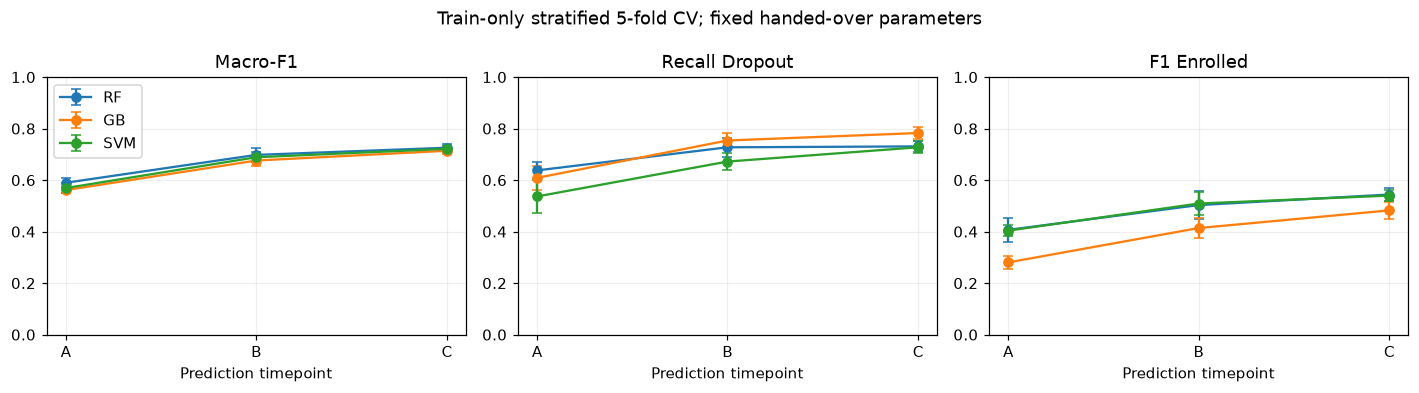

In [4]:
METRICS = ["f1_macro", "balanced_accuracy", "accuracy", "recall_Dropout", "f1_Enrolled", "train_f1_macro"]
summary = results.groupby(["model", "feature_set"])[METRICS].agg(["mean", lambda s: s.std(ddof=0)])
summary.columns = [f"{m}_{'std' if agg == '<lambda_0>' else agg}" for m, agg in summary.columns]
display(summary.round(4))
deltas = []
for name in ["RF", "GB", "SVM"]:
    wide = results.loc[results.model.eq(name)].pivot(index="fold", columns="feature_set", values="f1_macro")
    for a, b in [("A", "B"), ("B", "C")]:
        delta = wide[b] - wide[a]
        deltas.append({"model": name, "thay đổi": f"{a} → {b}",
                       "Δ Macro-F1 trung bình": delta.mean(), "SD Δ theo fold": delta.std(ddof=0),
                       "số fold tăng": int((delta > 0).sum())})
display(pd.DataFrame(deltas).round(4))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, metric, title in zip(axes, ["f1_macro", "recall_Dropout", "f1_Enrolled"],
                           ["Macro-F1", "Recall Dropout", "F1 Enrolled"]):
    for name in ["RF", "GB", "SVM"]:
        values = summary.loc[name].reindex(["A", "B", "C"])
        ax.errorbar(["A", "B", "C"], values[f"{metric}_mean"],
                    yerr=values[f"{metric}_std"], marker="o", capsize=3, label=name)
    ax.set(title=title, xlabel="Prediction timepoint", ylim=(0, 1))
    ax.grid(alpha=.2)
axes[0].legend()
fig.suptitle("Train-only stratified 5-fold CV; fixed handed-over parameters")
fig.tight_layout()
plt.show()

In [5]:
lines = []
for name in ["RF", "GB", "SVM"]:
    values = summary.loc[name]
    a, b, c = [values.loc[fs, "f1_macro_mean"] for fs in ["A", "B", "C"]]
    lines.append(f"- **{name}**: Macro-F1 A/B/C = {a:.4f}/{b:.4f}/{c:.4f}; "
                 f"B−A = {b-a:+.4f}, C−B = {c-b:+.4f}.")
display(Markdown("### Nhận xét từ lượt chạy\n" + "\n".join(lines) +
    "\n\nDùng mốc A/B để bàn về cảnh báo sớm, đồng thời báo mức đánh đổi chất lượng với C. "
    "Kết quả có điều kiện theo các cấu hình đã chọn trên C; không kết luận A/B đã được tối ưu. "
    "Khác biệt nhỏ cần xem độ lệch chuẩn và từng fold, không tự suy ra ý nghĩa thống kê. "
    "Hold-out chưa được chấm điểm."))

### Nhận xét từ lượt chạy
- **RF**: Macro-F1 A/B/C = 0.5896/0.6978/0.7256; B−A = +0.1082, C−B = +0.0278.
- **GB**: Macro-F1 A/B/C = 0.5611/0.6760/0.7139; B−A = +0.1148, C−B = +0.0379.
- **SVM**: Macro-F1 A/B/C = 0.5690/0.6887/0.7213; B−A = +0.1196, C−B = +0.0326.

Dùng mốc A/B để bàn về cảnh báo sớm, đồng thời báo mức đánh đổi chất lượng với C. Kết quả có điều kiện theo các cấu hình đã chọn trên C; không kết luận A/B đã được tối ưu. Khác biệt nhỏ cần xem độ lệch chuẩn và từng fold, không tự suy ra ý nghĩa thống kê. Hold-out chưa được chấm điểm.